<a href="https://colab.research.google.com/github/Fauzi455/PembelajaranMesin_2026/blob/main/JS-08/TUGAS/Tugas%20Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TUGAS LAB 2

In [22]:
from google.colab import files
uploaded = files.upload()

Saving iris.csv to iris.csv


In [23]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()
X = iris.data
y = iris.target
target_names = iris.target_names

#melakukan standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Bentuk data: {X.shape}")
print(f"Fitur: {iris.feature_names}")

Bentuk data: (150, 4)
Fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


Lakukan clustering dengan HDBSCAN

In [25]:
from sklearn.cluster import HDBSCAN

#inisialisasi dan fitting model HDBSCAN
#min_cluster_size menentukan ukuran minimal sampel dalam satu klaster
hdb = HDBSCAN(min_cluster_size=5)
labels = hdb.fit_predict(X_scaled)

Melaporkan hasilnya

Jumlah cluster yang terbentuk : 2
Banyaknya noise (-1)         : 2


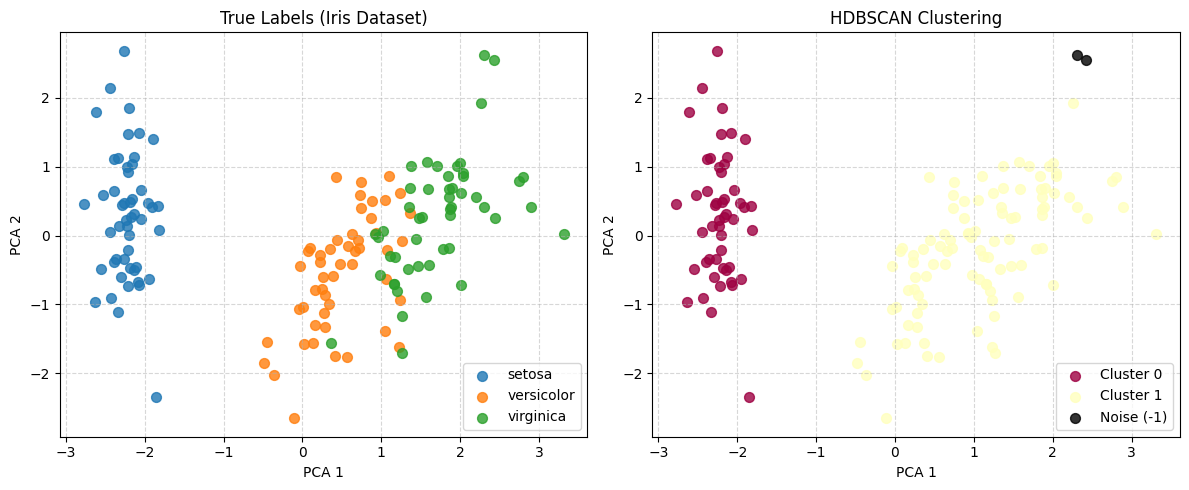

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

#jumlah klaster yang terbentuk
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

#banyaknya noise
n_noise = list(labels).count(-1)

print(f"Jumlah cluster yang terbentuk : {n_clusters}")
print(f"Banyaknya noise (-1)         : {n_noise}")

#visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(12, 5))

#plot label asli
plt.subplot(1, 2, 1)
for i, target_name in enumerate(target_names):
    plt.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=target_name, s=50, alpha=0.8)
plt.title('True Labels (Iris Dataset)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

#plot hasil HDBSCAN Clustering
plt.subplot(1, 2, 2)
unique_labels = set(labels)
colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]

for k, col in zip(unique_labels, colors):
    if k == -1:
        col = [0, 0, 0, 1]  #titik hitam untuk data noise
        label_name = 'Noise (-1)'
    else:
        label_name = f'Cluster {k}'

    mask = (labels == k)
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1], c=[col], label=label_name, s=50, alpha=0.8)

plt.title('HDBSCAN Clustering')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Analisis singkat : apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?

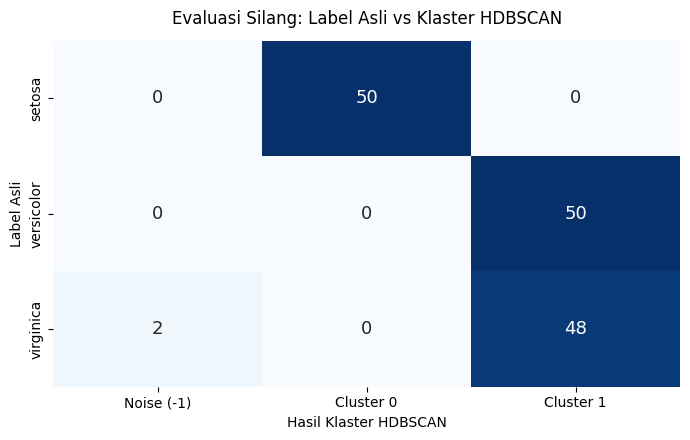

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

nama_kolom = {-1: 'Noise (-1)', 0: 'Cluster 0', 1: 'Cluster 1'}
cross_tab_tampil = cross_tab.rename(columns=nama_kolom)

plt.figure(figsize=(7, 4.5))
sns.heatmap(
    cross_tab_tampil,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    annot_kws={'size': 13}
)

plt.title('Evaluasi Silang: Label Asli vs Klaster HDBSCAN', fontsize=12, pad=12)
plt.xlabel('Hasil Klaster HDBSCAN', fontsize=10)
plt.ylabel('Label Asli', fontsize=10)
plt.tight_layout()
plt.show()

Tidak sepenuhnya sesuai, karena dataset asli memiliki 3 kelas yaitu setosa, versicolor, dan virginica, sedangkan HDBSCAN hanya mendeteksi 2 klaster utama serta 2 titik noise. Spesies Setosa berhasil dipisahkan dengan baik pada Cluster 0 karena secara spasial terpisah jauh dari spesies lainnya. Untuk Versicolor dan Virginica digabungkan menjadi satu kelompok pada Cluster 1. Hal ini terjadi karena algoritma berbasis densitas seperti HDBSCAN mengelompokkan area dengan kerapatan data yang bersambung.